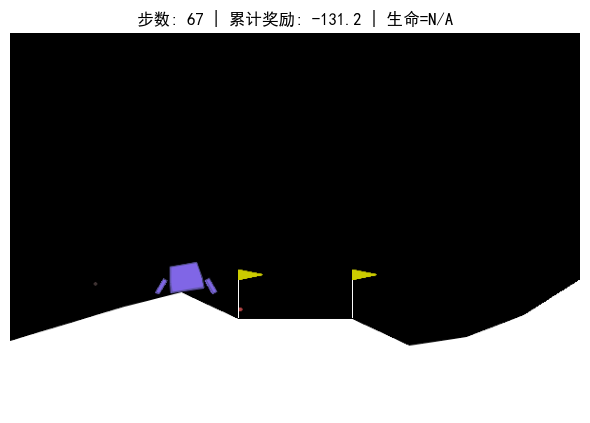

🏁 回合结束！
   - 总步数: 67
   - 最终累计奖励: -131.23
   - 终止原因: 自然结束(成功/失败)


In [2]:
import gymnasium as gym
import matplotlib.pyplot as plt
from IPython import display
import time

# 设置中文显示
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

# 创建环境，这里采用离散动作模式（4个动作）
env = gym.make("LunarLander-v3", render_mode="rgb_array")
obs, info = env.reset()

# 准备画布
fig, ax = plt.subplots(figsize=(6, 6))
img = ax.imshow(env.render())
ax.axis("off")
ax.set_title("月面着陆器 - 自动飞行中")
plt.tight_layout()
display.display(fig)

total_reward = 0
step_count = 0

# 开始自动循环执行，直到回合结束
while True:
    # 随机选择动作（如果想看智能体乱飞的样子就保持这个）
    action = env.action_space.sample()
    
    # 执行动作
    obs, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    step_count += 1
    
    # 刷新画面
    img.set_data(env.render())
    ax.set_title(f"步数: {step_count} | 累计奖励: {total_reward:.1f} | 生命={info.get('lives', 'N/A')}")
    display.clear_output(wait=True)
    display.display(fig)
    time.sleep(0.02)  # 稍微暂停一下，防止刷新过快看不清
    
    # 判断是否结束
    if terminated or truncated:
        break

# 打印结束总结
print(f"🏁 回合结束！")
print(f"   - 总步数: {step_count}")
print(f"   - 最终累计奖励: {total_reward:.2f}")
print(f"   - 终止原因: {'自然结束(成功/失败)' if terminated else '被截断(超时)'}")

# 释放资源
env.close()
plt.close(fig)